In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import gaussian_kde
from util import *

Go to the repo main and execute the following command:
```
python scripts/stochastic_model/abc_smc_full_timeline.py 0 10 demo final_run --final_run
```

In [2]:
model_dict = final_run_dict("demo")

10


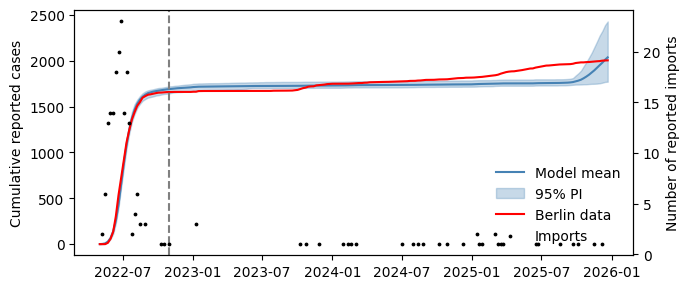

In [9]:
fig, ax = plt.subplots(figsize=(7, 3))

ax.plot(t_label,model_dict["diagnosis"].cumsum(axis = 1).mean(), color = "steelblue", label = "Model mean")

ax.fill_between(t_label,
                model_dict["diagnosis"].cumsum(axis = 1).quantile(0.025).to_numpy(dtype=float),
                model_dict["diagnosis"].cumsum(axis = 1).quantile(0.975).to_numpy(dtype=float),
                color = "steelblue",
                alpha = 0.3,
                label = "95% PI")

ax.plot(t_label, np.cumsum(berlin_mpox_all["reported_cases"]), color = "red", label = "Berlin data")
ax.axvline(t_label[26], linestyle = "dashed", color = "grey")

ax.set_ylabel("Cumulative reported cases")
ax.legend(frameon=False, ncol = 3, bbox_to_anchor=(1.1, 1.1), loc = "upper right")
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

ax.spines[['right']].set_visible(True)
ax2 = ax.twinx()

mask = (imports_t != 0)
ax2.scatter(t_label[mask], imports_t[mask], color = "black", s = 3, label = "Imports")
ax2.set_ylabel("Number of reported imports")

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1+h2, l1+l2, frameon=False)
plt.tight_layout()
plt.show()